order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
Median 1-month retention: 0.51%
Best cohort at month 3: 2017-06
Month 3 retention: 0.43%


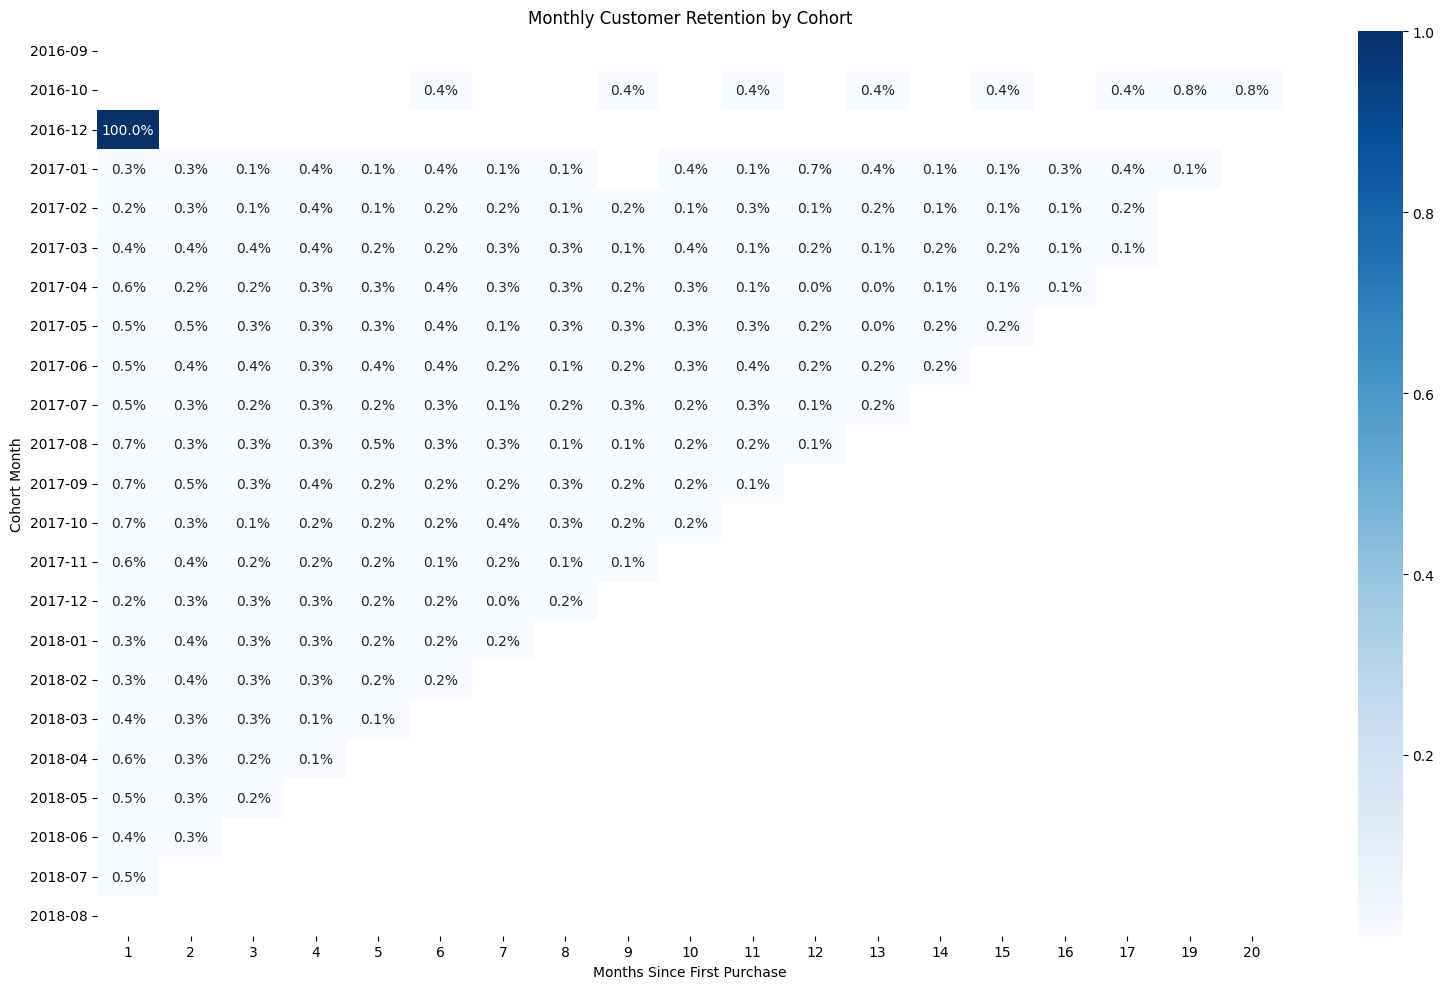

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Загружаем данные
customers = pd.read_csv('olist_customers_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')


# Проверяем распределение заказов по статусам
print(orders['order_status'].value_counts())


# Для retention учитываем успешно завершённые заказы
orders = orders.query("order_status == 'delivered'").copy()


# Работа с датой покупки
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)


# Добавляем настоящий уникальный ID пользователя
df = orders.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)


# Месяц заказа
df['order_month'] = (
    df['order_purchase_timestamp']
    .dt.to_period('M')
)


# Месяц первой покупки пользователя = когорта
df['cohort_month'] = (
    df.groupby('customer_unique_id')['order_month']
      .transform('min')
)


# Номер месяца относительно первой покупки
df['cohort_index'] = (
    (df['order_month'].dt.year - df['cohort_month'].dt.year) * 12
    + (df['order_month'].dt.month - df['cohort_month'].dt.month)
)


# Количество уникальных клиентов
cohort_data = (
    df.groupby(['cohort_month', 'cohort_index'])
      ['customer_unique_id']
      .nunique()
      .reset_index(name='customers')
)


# Когортная таблица
cohort_counts = cohort_data.pivot(
    index='cohort_month',
    columns='cohort_index',
    values='customers'
)


# Retention
cohort_sizes = cohort_counts[0]

retention = cohort_counts.divide(
    cohort_sizes,
    axis=0
)


# Медианный retention первого месяца
median_retention_1 = retention[1].median()

print(
    f'Median 1-month retention: '
    f'{median_retention_1:.2%}'
)


# Когорта с максимальным retention на третий месяц
best_cohort = retention[3].idxmax()
best_retention = retention.loc[best_cohort, 3]

print(
    f'Best cohort at month 3: {best_cohort}'
)
print(
    f'Month 3 retention: {best_retention:.2%}'
)


# Визуализация
plt.figure(figsize=(16, 10))

sns.heatmap(
    retention.iloc[:, 1:],
    annot=True,
    fmt='.1%',
    cmap='Blues'
)

plt.title('Monthly Customer Retention by Cohort')
plt.xlabel('Months Since First Purchase')
plt.ylabel('Cohort Month')

plt.tight_layout()
plt.show()

In [ ]:
mean_retention = retention.mean()
median_retention = retention.median()

retention_summary = pd.DataFrame({
    'mean_retention': mean_retention,
    'median_retention': median_retention
})

retention_summary.head(10)

,mean_retention,median_retention
cohort_index,,
0,1.000000,1.000000
1,0.054519,0.005075
2,0.003370,0.003261
3,0.002506,0.002711
4,0.002883,0.002910
5,0.002305,0.002079
6,0.002694,0.002457
7,0.002125,0.002305
8,0.002072,0.001870


In [ ]:
(retention_summary * 100).round(2)

,mean_retention,median_retention
cohort_index,,
0,100.00,100.00
1,5.45,0.51
2,0.34,0.33
3,0.25,0.27
4,0.29,0.29
5,0.23,0.21
6,0.27,0.25
7,0.21,0.23
8,0.21,0.19


In [ ]:
for month in range(1, min(7, retention.shape[1])):
    print(
        f'Month {month}: '
        f'mean = {retention[month].mean():.2%}, '
        f'median = {retention[month].median():.2%}'
    )

Month 1: mean = 5.45%, median = 0.51%
Month 2: mean = 0.34%, median = 0.33%
Month 3: mean = 0.25%, median = 0.27%
Month 4: mean = 0.29%, median = 0.29%
Month 5: mean = 0.23%, median = 0.21%
Month 6: mean = 0.27%, median = 0.25%


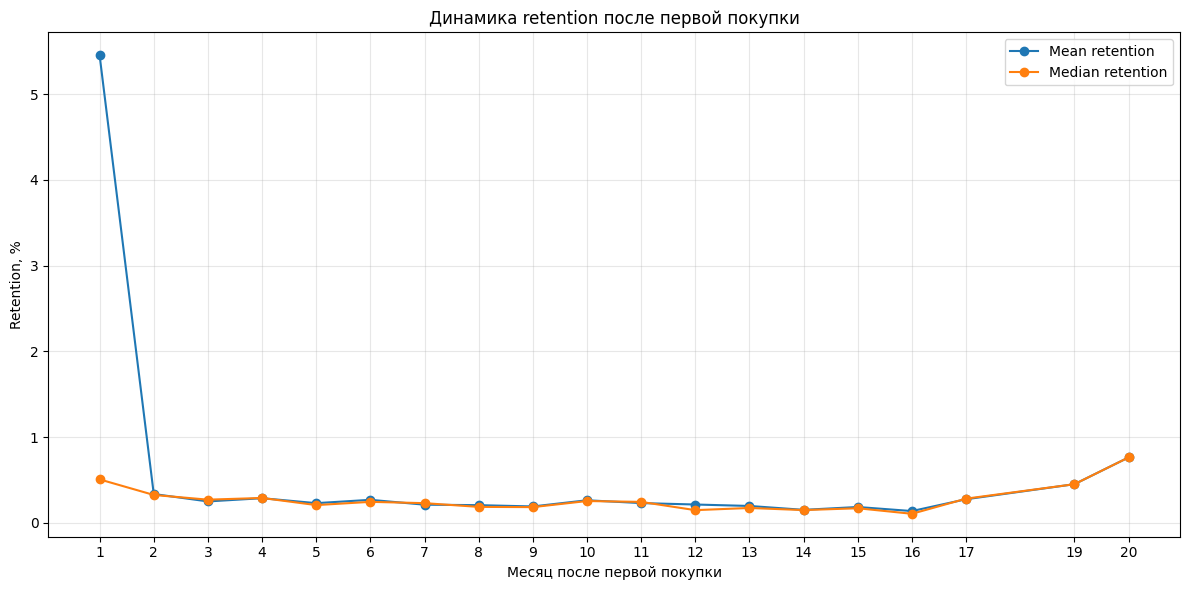

In [ ]:
import matplotlib.pyplot as plt

mean_retention = retention.iloc[:, 1:].mean()
median_retention = retention.iloc[:, 1:].median()

plt.figure(figsize=(12, 6))

plt.plot(
    mean_retention.index,
    mean_retention.values * 100,
    marker='o',
    label='Mean retention'
)

plt.plot(
    median_retention.index,
    median_retention.values * 100,
    marker='o',
    label='Median retention'
)

plt.title('Динамика retention после первой покупки')
plt.xlabel('Месяц после первой покупки')
plt.ylabel('Retention, %')

plt.xticks(mean_retention.index)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
orders_per_customer = (
    df.groupby('customer_unique_id')
      ['order_id']
      .nunique()
)

repeat_purchase_rate = (
    (orders_per_customer > 1).mean()
)

print(
    f'Доля клиентов с повторной покупкой: '
    f'{repeat_purchase_rate:.2%}'
)

Доля клиентов с повторной покупкой: 3.00%


In [ ]:
orders_per_customer.value_counts().sort_index().head(10)

,count
order_id,
1,90557
2,2573
3,181
4,28
5,9
6,5
7,3
9,1
15,1


In [ ]:
(
    orders_per_customer
    .value_counts(normalize=True)
    .sort_index()
    .head(10)
    .mul(100)
    .round(2)
)

,proportion
order_id,
1,97.00
2,2.76
3,0.19
4,0.03
5,0.01
6,0.01
7,0.00
9,0.00
15,0.00


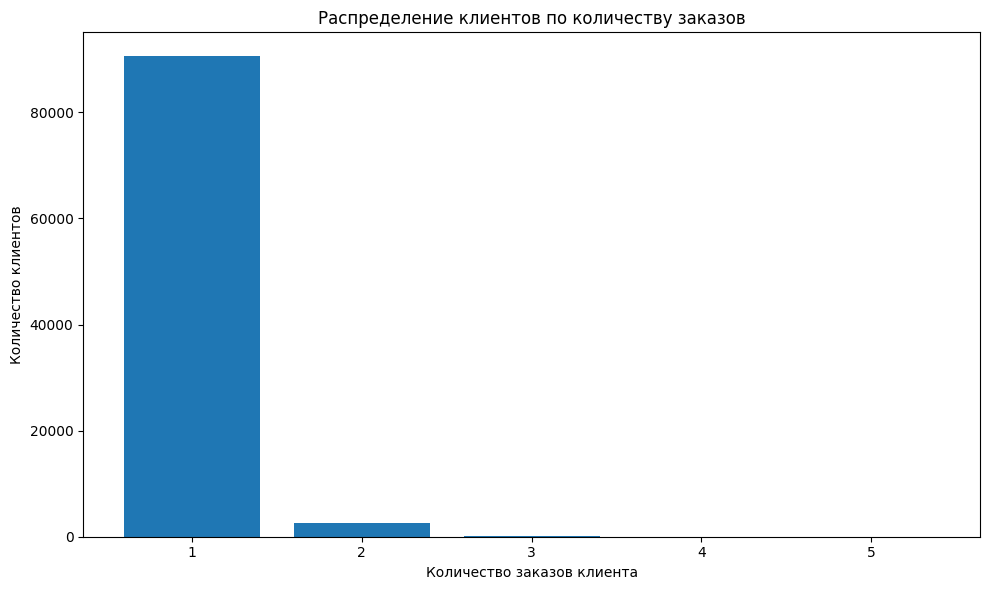

In [ ]:
customer_order_distribution = (
    orders_per_customer
    .value_counts()
    .sort_index()
)

customer_order_distribution = customer_order_distribution[
    customer_order_distribution.index <= 5
]

plt.figure(figsize=(10, 6))

plt.bar(
    customer_order_distribution.index.astype(str),
    customer_order_distribution.values
)

plt.title('Распределение клиентов по количеству заказов')
plt.xlabel('Количество заказов клиента')
plt.ylabel('Количество клиентов')

plt.tight_layout()
plt.show()

In [ ]:
print(f'Median month 1 retention: {retention[1].median():.2%}')
print(f'Mean month 1 retention: {retention[1].mean():.2%}')
print(f'Repeat purchase rate: {repeat_purchase_rate:.2%}')

Median month 1 retention: 0.51%
Mean month 1 retention: 5.45%
Repeat purchase rate: 3.00%


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.read_csv('olist_customers_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')

orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

# Оставляем успешно завершенные заказы
orders_delivered = orders.query(
    "order_status == 'delivered'"
).copy()

# Добавляем уникальный ID пользователя
orders_delivered = orders_delivered.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# Месяц покупки
orders_delivered['order_month'] = (
    orders_delivered['order_purchase_timestamp']
    .dt.to_period('M')
)

In [ ]:
orders_items = orders_delivered.merge(
    items[['order_id', 'price']],
    on='order_id',
    how='inner'
)

monthly_gmv = (
    orders_items
    .groupby('order_month')['price']
    .sum()
)

monthly_gmv.head()

,price
order_month,
2016-09,134.97
2016-10,40325.11
2016-12,10.90
2017-01,111798.36
2017-02,234223.40


In [ ]:
monthly_buyers = (
    orders_delivered
    .groupby('order_month')['customer_unique_id']
    .nunique()
)

monthly_buyers.head()

,customer_unique_id
order_month,
2016-09,1
2016-10,262
2016-12,1
2017-01,718
2017-02,1630


In [ ]:
customers_by_month = (
    orders_delivered
    .groupby('order_month')['customer_unique_id']
    .apply(set)
)

Метрика 3. Conversion to First Purchase

Третья метрика должна отражать заинтересованность новых клиентов в продукте.

Для этого предлагается использовать Conversion to First Purchase — долю новых пользователей, которые после первого посещения маркетплейса совершают первую покупку.

In [ ]:
monthly_retention = {}

months = sorted(customers_by_month.index)

for i in range(1, len(months)):

    previous_month = customers_by_month[months[i - 1]]
    current_month = customers_by_month[months[i]]

    retained_customers = (
        previous_month & current_month
    )

    retention_rate = (
        len(retained_customers) /
        len(previous_month)
    )

    monthly_retention[months[i]] = retention_rate

monthly_retention = pd.Series(monthly_retention)

In [ ]:
(monthly_retention * 100).round(2)

,0
2016-10,0.00
2016-12,0.00
2017-01,100.00
2017-02,0.28
2017-03,0.18
2017-04,0.44
2017-05,0.62
2017-06,0.46
2017-07,0.52
2017-08,0.60


In [ ]:
gmv_per_buyer = (
    monthly_gmv /
    monthly_buyers
)

gmv_per_buyer.head()

,0
order_month,
2016-09,134.970000
2016-10,153.912634
2016-12,10.900000
2017-01,155.708022
2017-02,143.695337


In [ ]:
metrics = pd.DataFrame({
    'GMV': monthly_gmv,
    'Paying_users': monthly_buyers,
    'Retention': monthly_retention,
    'GMV_per_paying_user': gmv_per_buyer
})

metrics

,GMV,Paying_users,Retention,GMV_per_paying_user
2016-09,134.97,1,NaN,134.970000
2016-10,40325.11,262,0.000000,153.912634
2016-12,10.90,1,0.000000,10.900000
2017-01,111798.36,718,1.000000,155.708022
2017-02,234223.40,1630,0.002786,143.695337
2017-03,359198.85,2508,0.001840,143.221232
2017-04,340669.68,2274,0.004386,149.810765
2017-05,489338.25,3479,0.006157,140.654858
2017-06,421923.37,3076,0.004599,137.166245
2017-07,481604.52,3802,0.005202,126.671362


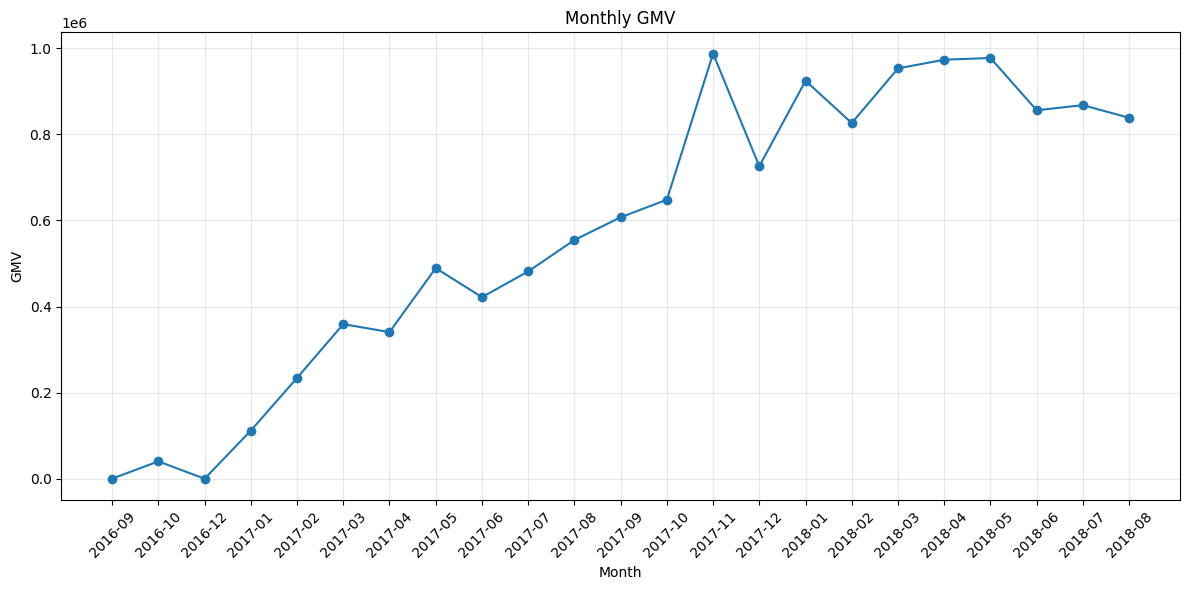

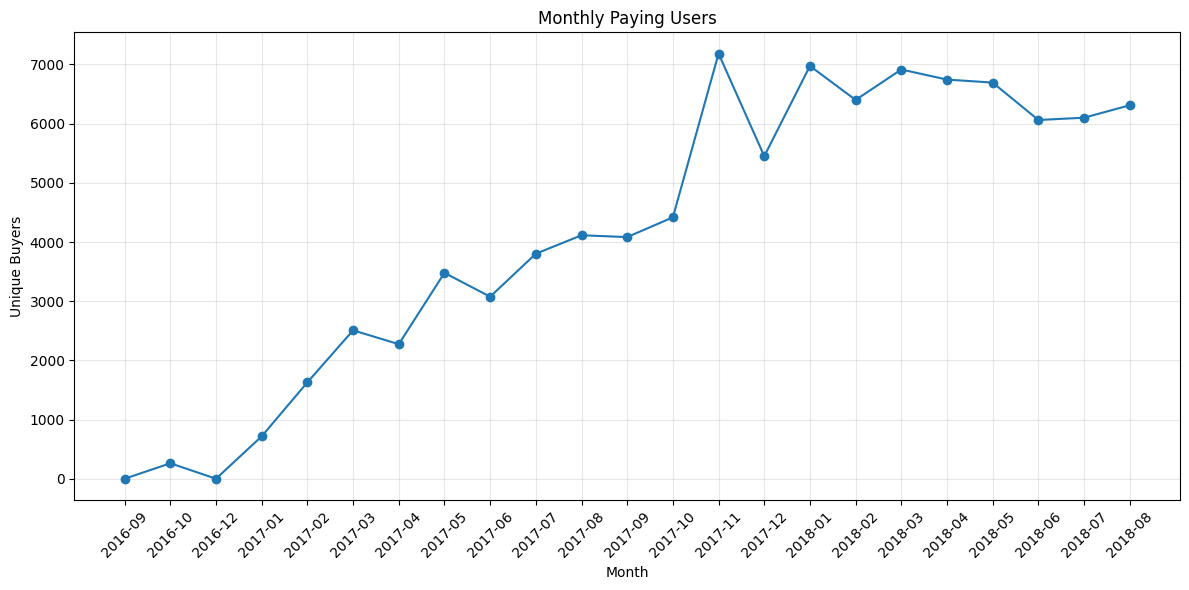

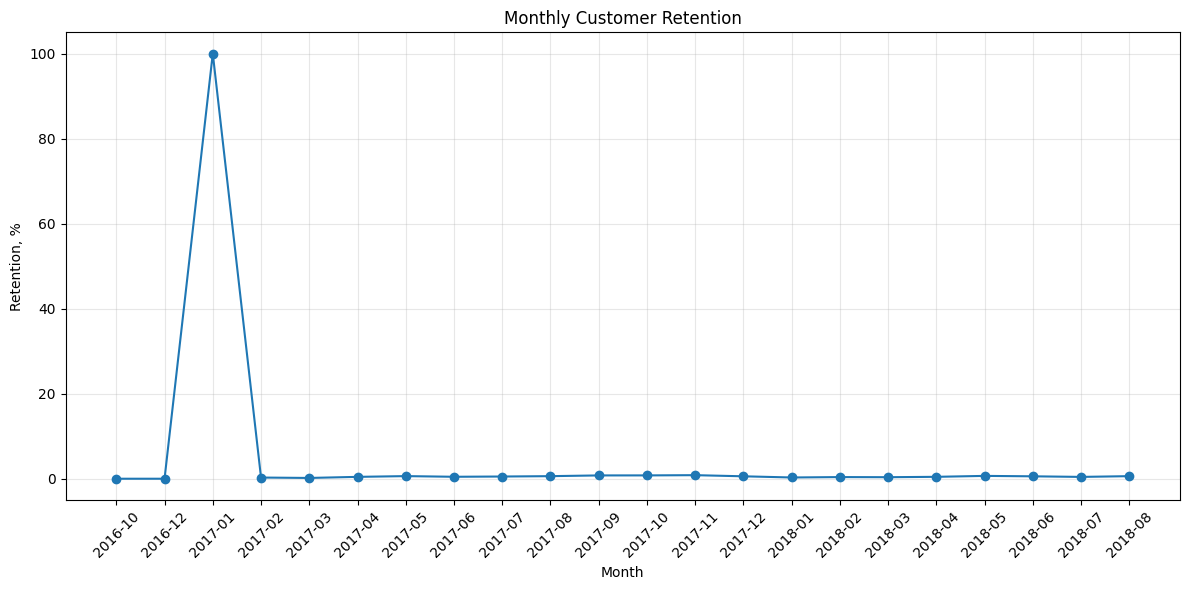

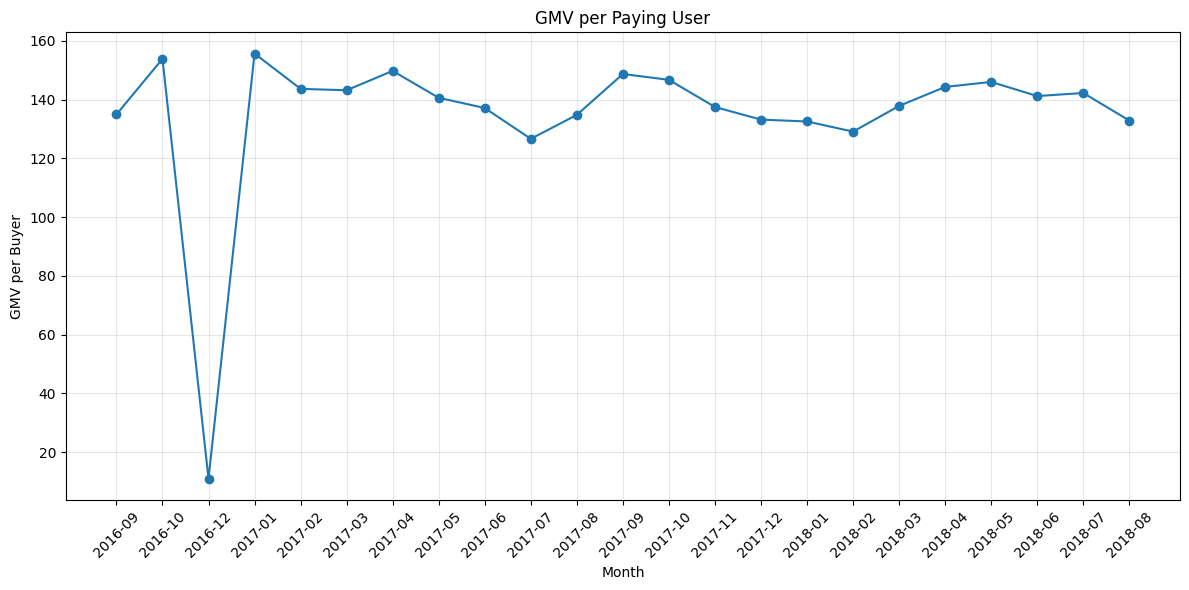

In [ ]:
import matplotlib.pyplot as plt


# 1. GMV
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_gmv.index.astype(str),
    monthly_gmv.values,
    marker='o'
)

plt.title('Monthly GMV')
plt.xlabel('Month')
plt.ylabel('GMV')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Monthly Paying Users
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_buyers.index.astype(str),
    monthly_buyers.values,
    marker='o'
)

plt.title('Monthly Paying Users')
plt.xlabel('Month')
plt.ylabel('Unique Buyers')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 4. Monthly Retention Rate
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_retention.index.astype(str),
    monthly_retention.values * 100,
    marker='o'
)

plt.title('Monthly Customer Retention')
plt.xlabel('Month')
plt.ylabel('Retention, %')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 5. GMV per Paying User
plt.figure(figsize=(12, 6))

plt.plot(
    gmv_per_buyer.index.astype(str),
    gmv_per_buyer.values,
    marker='o'
)

plt.title('GMV per Paying User')
plt.xlabel('Month')
plt.ylabel('GMV per Buyer')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Результаты ICE:
                    Гипотеза  Прирост заказов  Confidence  Ease  Impact  ICE
   Исправление отмен заказов              499           8     6       4  192
         Новый способ оплаты              386           5     9       4  180
Сокращение задержек доставки               35          10     4       1   40


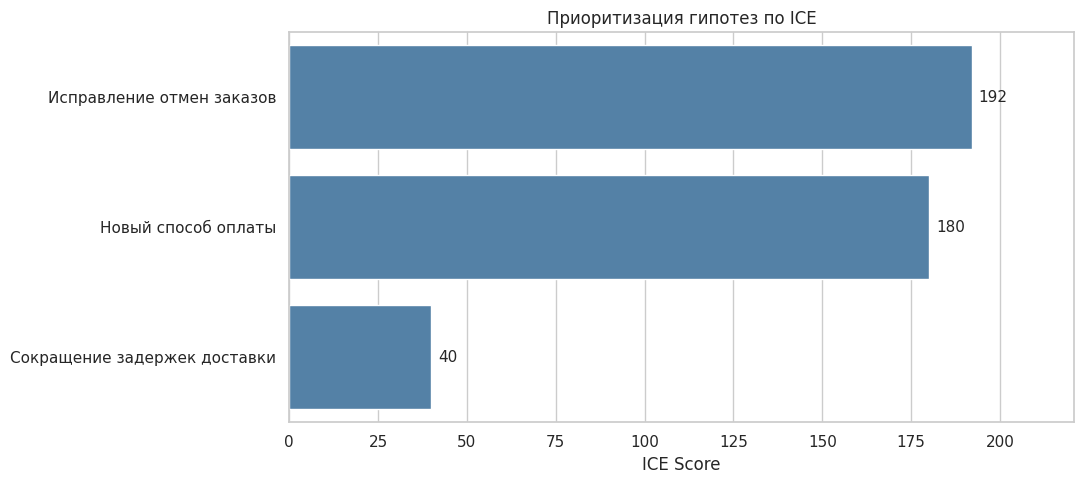


Приоритетная гипотеза:
Исправление отмен заказов
ICE: 192


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Загрузка данных
orders = pd.read_csv(
    'olist_orders_dataset.csv',
    parse_dates=[
        'order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
)

customers = pd.read_csv('olist_customers_dataset.csv')

# Объединяем таблицы
df = orders.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='inner',
    validate='many_to_one'
)

# Период анализа: с июня 2017 года
df = df[
    df['order_purchase_timestamp'] >= '2017-06-01'
].copy()

# Медианный retention M1 из задачи 1
median_retention = 0.004787710958260656

# 2. Гипотеза 1: устранение отмен
impact_metric_1 = (
    df['order_status'] == 'canceled'
).sum()

# 3. Гипотеза 2: устранение задержек
delivered = df[
    df['order_status'] == 'delivered'
].copy()

late_orders = delivered[
    delivered['order_delivered_customer_date']
    > delivered['order_estimated_delivery_date']
]

impact_metric_2 = (
    len(late_orders) * median_retention
)

# 4. Гипотеза 3: новый способ оплаты
orders_per_customer = (
    delivered.groupby('customer_unique_id')
    ['order_id'].nunique()
)

single_purchase_customers = (
    orders_per_customer == 1
).sum()

impact_metric_3 = (
    single_purchase_customers * median_retention
)

# 5. Шкала Impact
impact_limits = [
    50, 150, 350, 750, 1550,
    3150, 6350, 12750, 25550, 51150
]

def calculate_impact(value):
    value = round(value)
    for score, upper_limit in enumerate(impact_limits, start=1):
        if value <= upper_limit:
            return score
    return 10

# 6. Таблица ICE
hypotheses = pd.DataFrame({
    'Гипотеза': [
        'Исправление отмен заказов',
        'Сокращение задержек доставки',
        'Новый способ оплаты'
    ],
    'Прирост заказов': [
        impact_metric_1,
        impact_metric_2,
        impact_metric_3
    ],
    'Confidence': [8, 10, 5],
    'Ease': [6, 4, 9]
})

hypotheses['Impact'] = (
    hypotheses['Прирост заказов']
    .apply(calculate_impact)
)

hypotheses['ICE'] = (
    hypotheses['Impact']
    * hypotheses['Confidence']
    * hypotheses['Ease']
)

hypotheses = hypotheses.sort_values(
    'ICE', ascending=False
).reset_index(drop=True)

hypotheses['Прирост заказов'] = (
    hypotheses['Прирост заказов'].round().astype(int)
)

print('Результаты ICE:')
print(hypotheses.to_string(index=False))

# 7. Визуализация
sns.set_theme(style='whitegrid')

plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=hypotheses,
    x='ICE',
    y='Гипотеза',
    color='steelblue'
)

for i, row in hypotheses.iterrows():
    ax.text(
        row['ICE'] + 2,
        i,
        str(row['ICE']),
        va='center',
        fontsize=11
    )

plt.xlim(0, hypotheses['ICE'].max() * 1.15)
plt.xlabel('ICE Score')
plt.ylabel('')
plt.title('Приоритизация гипотез по ICE')
plt.tight_layout()
plt.show()

# 8. Выбор победителя
best = hypotheses.iloc[0]

print('\nПриоритетная гипотеза:')
print(best['Гипотеза'])
print('ICE:', best['ICE'])


### Метрики для проверки продуктовой гипотезы

**Гипотеза:** исправление технической ошибки процессинга заказов позволит сократить количество отмен и увеличить число успешно доставленных заказов, не ухудшая клиентский опыт.

Для проверки гипотезы предлагается провести A/B-тестирование и использовать следующие метрики.

**1. Целевая метрика — Delivery Success Rate (DSR).**

Доля успешно доставленных заказов от общего числа оформленных заказов.

Метрика непосредственно отражает основную цель гипотезы — увеличение количества успешно выполненных заказов. Ожидаемый результат — статистически значимый рост показателя в тестовой группе относительно контрольной.

**2. Прокси-метрика — Technical Cancellation Rate (TCR).**

Доля заказов, отменённых по техническим причинам, от общего числа оформленных заказов.

Метрика позволяет оценить непосредственную эффективность исправления ошибки процессинга. Ожидаемый результат — снижение доли технических отмен в тестовой группе.

**3. Guardrail-метрика — Late Delivery Rate (LDR).**

Доля заказов, доставленных позже обещанной даты, от общего числа доставленных заказов.

Метрика необходима для контроля качества клиентского опыта. Рост числа обрабатываемых заказов не должен приводить к ухудшению своевременности доставки. Ожидаемый результат — отсутствие существенного увеличения доли опоздавших доставок.

**Критерий успешности эксперимента:** статистически значимый рост Delivery Success Rate при снижении Technical Cancellation Rate и отсутствии недопустимого ухудшения Late Delivery Rate.

Таким образом, выбранные метрики позволят одновременно оценить эффективность исправления технической ошибки, достижение продуктовой цели и сохранение качества обслуживания покупателей.

Итоговый отчёт для продакт-менеджера: маркетплейс Olist

Цель: выявить причины стагнации товарооборота, оценить возвращаемость покупателей, выбрать первоочередное улучшение и определить показатели его проверки.
Источник данных: olist_orders_dataset.csv, olist_customers_dataset.csv, olist_order_items_dataset.csv.
Методология: покупка — заказ со статусом delivered; покупатель — customer_unique_id; для retention используется месяц оформления заказа.

1. Формализация проблемы

Выручка маркетплейса несколько месяцев не растёт. Когортный анализ выявил крайне низкую долю повторных покупок: медианный M1 retention ≈ 0,48%; около 3% клиентов совершили более одного доставленного заказа за период наблюдения. Слабая возвращаемость означает, что устойчивый рост может требовать постоянного привлечения новой аудитории.

Оговорка: Olist — маркетплейс с неоднородными категориями товаров; низкий месячный retention не доказывает отсутствия product/market fit сам по себе. Потребуются анализ частоты покупок по категориям, опыта клиентов и юнит-экономики.

2. Результаты исследования (задачи 1–5)

Шаг	Результат
1. Retention	Медианный M1 retention ≈ 0,48%; максимальный M3 — когорта июня 2017 года, ≈ 0,43%.
2. Product/market fit	Не подтверждён данными о повторных покупках; требуется дополнительная проверка сегментов спроса и удовлетворённости.
3. Метрики роста	GMV (товарный оборот), MPU (платящие покупатели за месяц), Conversion to First Purchase, M1 Retention, ARPPU. Конверсию первой покупки пока нельзя оценить без данных о посетителях.
4. ICE	Исправление ошибок процессинга: 192; новый способ оплаты: 180; сокращение задержек: 40. Первая гипотеза — приоритетная.
5. A/B-тест	Целевая — Delivery Success Rate; прокси — Technical Cancellation Rate; guardrail — Late Delivery Rate.
Важно: GMV и ARPPU на базе сумм price — это показатели товарооборота, а не чистого дохода маркетплейса. ICE оценивает потенциальный эффект, а не доказанную причинную связь. Расчёт 499 отменённых заказов — верхняя оценка эффекта при нереалистично строгом допущении, что удастся устранить все отмены.

3. Рекомендации и последовательность действий

Исправить процессинг заказов. Разделить причины отмен на технические и остальные; протестировать исправление на контрольной и тестовой группах. Цель — увеличение доли успешных доставок без роста доли опозданий.
Разобраться в низком retention. Провести сегментацию по категориям, частоте потребности, размерам покупок и срокам доставки; изучить жалобы и причины отказа от повторной покупки.
Улучшить опыт повторной покупки. Проверять персональные рекомендации, удобство повторного заказа и релевантность ассортимента через контролируемые эксперименты — без навязчивых уведомлений.
Развернуть мониторинг. Ежемесячно отслеживать GMV, MPU, M1 retention, ARPPU и воронку первой покупки; добавить сбор событий посещения/регистрации и причин отмен.
Проверять прибыльность. Отдельно измерять комиссионную выручку, маржинальный доход, CAC, LTV и стоимость исполнения заказа. Масштабировать только сегменты с подтверждённым спросом и устойчивой экономикой.
Решение для продакта

Сейчас: сначала повысить надёжность выполнения заказов и получить экспериментальное подтверждение эффекта. Далее: сосредоточиться на повторных покупках и сегментах, где есть подтверждённый спрос. Не рекомендовано: масштабирование на новые рынки до проверки unit economics и устойчивой возвращаемости.